# Klasifikasi Domain Berbasis Punycode untuk Identifikasi Serangan Phishing Menggunakan Naive Bayes

## Studi eksperimen dengan data sintetis dan nyata

Notebook ini merupakan dokumen eksperimen utama sekaligus dokumentasi penelitian. Alur mencakup kajian penelitian terdahulu, audit data, pembentukan data sintetis, EDA, preprocessing, feature engineering URL/Punycode, perbandingan keluarga Naive Bayes, evaluasi real-only, penyimpanan model, dan pengujian prediksi.

## 1. Penelitian terdahulu dan posisi penelitian

| Penelitian | Cara mendeteksi | Keterbatasan/celah yang diambil |
|---|---|---|
| Le et al. (2018), **URLNet** | CNN pada karakter dan kata URL untuk mempelajari representasi URL secara end-to-end. | Kuat untuk pola URL umum, tetapi Punycode/homograph bukan fokus eksplisit dan komputasinya lebih berat daripada Naive Bayes. |
| Mamun et al. (2019), **Using Lexical Features for Malicious URL Detection** | Fitur leksikal URL untuk keputusan real-time tanpa memuat halaman. | Fokus malicious URL umum; hubungan skrip Unicode, IDNA, dan homograph perlu lapisan khusus. |
| Suzuki et al. (2019), **ShamFinder** | Membentuk basis data homoglyph otomatis dan mencari IDN yang menyerupai domain lain. | Sangat relevan untuk homograph, tetapi bukan klasifikasi phishing URL lengkap dengan path/query. |
| Sawabe et al. (2019) | OCR membandingkan tampilan IDN dengan domain legitimate sehingga tidak hanya bergantung pada tabel manual. | Memerlukan pemrosesan visual/OCR; penelitian ini memilih skeleton Unicode yang lebih ringan. |
| Yazdani et al. (2020) | Tabel homoglyph yang diperluas + karakteristik domain + active DNS measurements. | Membutuhkan data DNS aktif; penelitian ini sengaja dapat berjalan offline hanya dari URL. |
| Hu et al. (2021) | Mengevaluasi kebijakan browser terhadap mixed-script, skeleton, confusable, dan tampilan Punycode. | Pertahanan browser tidak selalu sama dan bukan model klasifikasi data phishing. |
| Tupsamudre et al. (2021), **PhishMatch** | Pertahanan berlapis: exact/approximate string matching, n-gram, whitelist, konteks, dan ML. | Menguatkan alasan pendekatan berlapis; penelitian ini memfokuskan kontribusi pada IDN/Punycode dan Naive Bayes ringan. |

### Sumber primer

1. [URLNet, arXiv:1802.03162](https://arxiv.org/abs/1802.03162)  
2. [Using Lexical Features for Malicious URL Detection, arXiv:1910.06277](https://arxiv.org/abs/1910.06277)  
3. [ShamFinder, arXiv:1909.07539](https://arxiv.org/abs/1909.07539)  
4. [Detection Method of Homograph IDNs with OCR](https://www.jstage.jst.go.jp/article/ipsjjip/27/0/27_536/_article/-char/en)  
5. [A Case of Identity, DOI 10.1109/EuroSPW51379.2020.00082](https://doi.org/10.1109/EuroSPW51379.2020.00082)  
6. [Assessing Browser-level Defense against IDN-based Phishing, USENIX Security 2021](https://www.usenix.org/conference/usenixsecurity21/presentation/hu-hang)  
7. [PhishMatch, arXiv:2112.02226](https://arxiv.org/abs/2112.02226)

### Kebaruan yang diuji

Penelitian ini tidak menyatakan semua Punycode sebagai phishing. URL umum dipelajari dengan TF-IDF character n-gram dan indikator struktur URL menggunakan Naive Bayes. Punycode ditambahkan sebagai fokus melalui data IDN legitimate dan homograph phishing yang seimbang, decoding IDNA, identifikasi skrip, serta skeleton confusable. Dengan demikian, keluaran tetap satu label—legitimate atau phishing—tetapi keputusannya menggunakan bukti statistik dan guard Unicode.

## 2. Import dan konfigurasi eksperimen

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import html, ipaddress, json, random, re, unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, average_precision_score,
    classification_report, confusion_matrix, precision_recall_fscore_support,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB

ROOT = Path.cwd()
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 100)
print('Folder penelitian:', ROOT)

Folder penelitian: D:\Gumelar Akhirul\Coding\ProjectHibah_NaiveBayes


**Interpretasi:** seed dibuat tetap agar sampling dan split dapat direplikasi. Semua algoritma yang dibandingkan masih berada dalam keluarga Naive Bayes sesuai ruang lingkup judul.

## 3. Generator data sintetis (reproducible)

In [2]:
# Reproducible synthetic-data generator (disabled because CSV final already exists).
import csv

LIMIT = 50_000
SCRIPTS = {
    "cyrillic": ["магазин", "новости", "почта", "книга", "музыка", "город"],
    "greek": ["παράδειγμα", "αγορά", "μουσική", "βιβλίο", "ταξίδι", "πόλη"],
    "armenian": ["օրինակ", "խանութ", "երաժշտություն", "գիրք", "քաղաք"],
    "thai": ["ตัวอย่าง", "ร้านค้า", "หนังสือ", "ดนตรี", "เมือง"],
}
CONFUSABLES = {
    "a":["а","α"], "c":["с"], "e":["е","ε"], "i":["і","ι"], "l":["ӏ"],
    "o":["о","ο","օ"], "p":["р","ρ"], "s":["ѕ"], "x":["х","χ"], "y":["у"]
}
TLDS = ["com","net","org","info","online","site"]

def encode_idn(label):
    return label.encode("idna").decode("ascii")

def mutate_homograph(label, rng):
    positions = [i for i,c in enumerate(label) if c in CONFUSABLES]
    chosen = set(rng.sample(positions, rng.randint(1, min(3,len(positions)))))
    return "".join(rng.choice(CONFUSABLES[c]) if i in chosen else c
                   for i,c in enumerate(label))

def build_synthetic(limit=LIMIT, seed=SEED):
    rng = random.Random(seed)
    legitimate, phishing = set(), set()
    script_items = list(SCRIPTS.items())
    while len(legitimate) < limit:
        script, words = rng.choice(script_items)
        label = f"{rng.choice(words)}{rng.randrange(1,10_000_000)}"
        url = f"https://{encode_idn(label)}.{rng.choice(TLDS)}/{rng.choice(['','about','news','products'])}"
        legitimate.add((url, "legitimate", "synthetic_native_idn", script))
    source_domains = pd.read_csv("tranco_6WNKX.csv", header=None,
                                 names=["rank","domain"], dtype=str)
    domains = source_domains.domain.dropna().astype(str).str.lower().sample(
        frac=1, random_state=seed
    )
    for domain in domains:
        first, *suffix = domain.split(".")
        if first.startswith("xn--") or not any(c in CONFUSABLES for c in first):
            continue
        try:
            fake = encode_idn(mutate_homograph(first, rng))
        except UnicodeError:
            continue
        host = ".".join([fake] + suffix)
        url = f"https://{host}/{rng.choice(['login','verify','account/update','password/reset'])}"
        phishing.add((url, "phishing", "synthetic_homograph", "mixed_confusable"))
        if len(phishing) == limit:
            break
    columns = ["url","label","source","script"]
    return pd.DataFrame(legitimate, columns=columns), pd.DataFrame(phishing, columns=columns)

REGENERATE_SYNTHETIC = False
if REGENERATE_SYNTHETIC:
    generated_legit, generated_phish = build_synthetic()
    generated_legit.to_csv("synthetic_legitimate_50000.csv", index=False)
    generated_phish.to_csv("synthetic_phishing_50000.csv", index=False)
    print(len(generated_legit), len(generated_phish))
else:
    print("Memakai CSV sintetis final; ubah REGENERATE_SYNTHETIC=True untuk membuat ulang.")

Memakai CSV sintetis final; ubah REGENERATE_SYNTHETIC=True untuk membuat ulang.


**Interpretasi:** generator memisahkan konsep label. Legitimate memakai nama native IDN yang bukan tiruan merek, sedangkan phishing mengganti karakter domain dengan homoglyph dan menambahkan path sensitif. Hasil disimpan hanya jika `REGENERATE_SYNTHETIC=True`, sehingga eksekusi biasa tidak menimpa dataset final.

## 4. Memuat 50.000 data nyata per kelas

In [3]:
tranco = pd.read_csv(ROOT/'tranco_6WNKX.csv', header=None,
                     names=['rank','domain'], dtype=str)
real_phish_all = (pd.read_csv(ROOT/'verified_online.csv', usecols=['url'])
                  .dropna().drop_duplicates('url'))
phish_hosts = set(real_phish_all.url.map(lambda x:
    (urlsplit(x if '://' in x else 'https://'+x).hostname or '').lower()))
real_phish = (real_phish_all.sample(50_000, random_state=SEED)
              .assign(label=1, source='phishtank_real'))
real_legit = pd.DataFrame({
    'url': 'https://' + tranco['domain'].str.strip(),
    'label': 0, 'source': 'tranco_real'
}).dropna().drop_duplicates('url')
real_legit = real_legit[~real_legit.url.map(lambda x:
    (urlsplit(x).hostname or '').lower()).isin(phish_hosts)]
real_legit = real_legit.sample(50_000, random_state=SEED)
real = pd.concat([real_legit, real_phish], ignore_index=True)
real.groupby(['source','label']).size().rename('jumlah')

source          label
phishtank_real  1        50000
tranco_real     0        50000
Name: jumlah, dtype: int64

**Interpretasi:** masing-masing sumber menyumbang tepat 50.000 URL unik. Tranco adalah proksi legitimate dan PhishTank adalah phishing terverifikasi pada snapshot; keduanya tetap memiliki keterbatasan label sumber.

## 5. Memuat dan memvalidasi data sintetis

In [4]:
synth_legit = pd.read_csv(ROOT/'synthetic_legitimate_50000.csv')
synth_phish = pd.read_csv(ROOT/'synthetic_phishing_50000.csv')
synthetic = pd.concat([synth_legit, synth_phish], ignore_index=True)
synthetic['label'] = synthetic['label'].map({'legitimate':0, 'phishing':1})

audit_sintetis = pd.DataFrame({
    'baris': [len(synth_legit), len(synth_phish)],
    'url_unik': [synth_legit.url.nunique(), synth_phish.url.nunique()],
    'duplikat': [synth_legit.duplicated('url').sum(), synth_phish.duplicated('url').sum()],
    'missing': [synth_legit.isna().sum().sum(), synth_phish.isna().sum().sum()]
}, index=['legitimate','phishing'])
audit_sintetis

,baris,url_unik,duplikat,missing
legitimate,50000,50000,0,0
phishing,50000,50000,0,0


**Interpretasi:** kedua kelas harus menunjukkan 50.000 baris, 50.000 URL unik, nol duplikat, dan nol missing value. Sintetis legitimate dibuat sebagai IDN native/non-homograph; sintetis phishing dibuat sebagai mutasi visual domain beragam. Ini memperbaiki dataset lama yang keliru melabeli homograph merek sebagai legitimate.

## 6. EDA dan pemeriksaan kualitas gabungan

source                label
phishtank_real        1        50000
synthetic_homograph   1        50000
synthetic_native_idn  0        50000
tranco_real           0        50000
Name: jumlah, dtype: int64

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100000.0,31.71,10.8,12.0,21.0,33.0,42.0,76.0
1,100000.0,58.64,122.6,12.0,38.0,54.0,65.0,25523.0


Missing URL: 0
Duplikat URL lintas seluruh sumber: 0


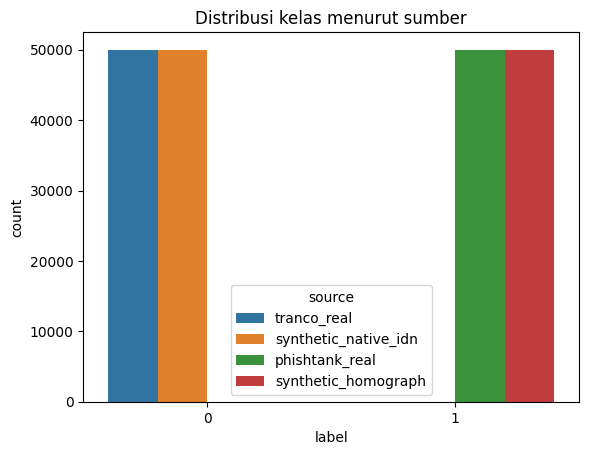

In [5]:
combined = pd.concat([real[['url','label','source']],
                          synthetic[['url','label','source']]], ignore_index=True)
combined['url_length'] = combined.url.str.len()
combined['host'] = combined.url.map(
    lambda x: (urlsplit(x if '://' in x else 'https://'+x).hostname or '').lower()
)
display(combined.groupby(['source','label']).size().rename('jumlah'))
display(combined.groupby('label').url_length.describe().round(2))
print('Missing URL:', combined.url.isna().sum())
print('Duplikat URL lintas seluruh sumber:', combined.url.duplicated().sum())
sns.countplot(data=combined, x='label', hue='source')
plt.title('Distribusi kelas menurut sumber'); plt.show()

**Interpretasi:** EDA memisahkan distribusi berdasarkan sumber agar keseimbangan total tidak menyembunyikan source bias. Panjang URL juga diperiksa karena URL phishing PhishTank memiliki path/query, sedangkan banyak URL Tranco hanya hostname.

## 7. Split real berbasis kelompok hostname

In [6]:
def hostname_of(value):
    parsed = urlsplit(value if '://' in value else 'https://'+value)
    return (parsed.hostname or '').lower().rstrip('.')

real['host'] = real.url.map(hostname_of)
train_parts, test_parts = [], []
for label in (0,1):
    part = real[real.label == label]
    split = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED)
    i_train, i_test = next(split.split(part, groups=part.host))
    train_parts.append(part.iloc[i_train])
    test_parts.append(part.iloc[i_test])

n_train = min(map(len, train_parts))
n_test = min(map(len, test_parts))
real_train = pd.concat([x.sample(n_train, random_state=SEED) for x in train_parts])
real_test = pd.concat([x.sample(n_test, random_state=SEED) for x in test_parts])
assert set(real_train.host).isdisjoint(set(real_test.host))
real_train.label.value_counts(), real_test.label.value_counts()

(label
 0    40000
 1    40000
 Name: count, dtype: int64,
 label
 0    7114
 1    7114
 Name: count, dtype: int64)

**Interpretasi:** pemisahan dilakukan sebelum penyeimbangan dan memakai hostname sebagai group. Karena itu dua URL dari host yang sama tidak dapat tersebar ke train dan test. Test akhir berisi 7.114 URL nyata per kelas.

## 8. Feature engineering: URL dan indikator phishing

In [7]:
SUSPICIOUS = {'login','signin','verify','verification','secure','account',
              'update','password','wallet','invoice','suspended','confirm'}

def prepare_url(value):
    raw = unicodedata.normalize('NFKC', html.unescape(str(value).strip())).lower()
    parsed = urlsplit(raw if '://' in raw else 'https://'+raw)
    host, pq, tokens = (parsed.hostname or '').rstrip('.'), f'{parsed.path}?{parsed.query}', []
    try:
        ipaddress.ip_address(host.strip('[]')); tokens.append('__host_ip__')
    except ValueError: pass
    if '@' in parsed.netloc: tokens.append('__at_symbol__')
    if host.count('.') >= 3: tokens.append('__many_subdomains__')
    if len(raw) >= 75: tokens.append('__long_url__')
    if host.startswith('xn--') or '.xn--' in host: tokens.append('__punycode__')
    if parsed.scheme == 'http': tokens.append('__plain_http__')
    if any(word in pq for word in SUSPICIOUS): tokens.append('__suspicious_path__')
    if re.search(r'%[0-9a-f]{2}', raw): tokens.append('__percent_encoding__')
    return raw + ' ' + ' '.join(tokens)

for sample in ['http://192.0.2.1/login?account=verify',
               'https://example.com/about', 'xn--gogle-jye.com']:
    print(prepare_url(sample))

http://192.0.2.1/login?account=verify __host_ip__ __many_subdomains__ __plain_http__ __suspicious_path__
https://example.com/about 
xn--gogle-jye.com __punycode__


**Interpretasi:** indikator tidak langsung memvonis phishing; indikator menjadi token tambahan yang dipelajari bersama character n-gram. NFKC menangani bentuk fullwidth, sedangkan `xn--` memberi sinyal Punycode tanpa menganggap seluruh Punycode berbahaya.

## 9. Vectorization dan training

In [8]:
train = pd.concat([real_train[['url','label']],
                   synthetic[['url','label']]], ignore_index=True)
train = train.sample(frac=1, random_state=SEED)

vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3,5),
    min_df=2, max_features=150_000, sublinear_tf=True, dtype=np.float32)
X_train = vectorizer.fit_transform(train.url.map(prepare_url))
X_test = vectorizer.transform(real_test.url.map(prepare_url))
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (180000, 150000) | Test: (14228, 150000)


**Interpretasi:** character n-gram 3–5 sesuai untuk URL karena dapat menangkap fragmen seperti `xn--`, nama merek, separator, path, dan variasi ejaan tanpa tokenisasi bahasa alami.

In [9]:
models = {
    'MultinomialNB': MultinomialNB(alpha=.05),
    'ComplementNB': ComplementNB(alpha=.05),
    'BernoulliNB': BernoulliNB(alpha=.05, binarize=.0)
}
results, fitted = {}, {}
for name, model in models.items():
    model.fit(X_train, train.label)
    proba = model.predict_proba(X_test)[:,1]
    pred = (proba >= .5).astype(int)
    p,r,f1,_ = precision_recall_fscore_support(real_test.label, pred,
                                                average='binary')
    results[name] = {
        'accuracy': accuracy_score(real_test.label,pred), 'precision':p,
        'recall':r, 'f1':f1, 'roc_auc':roc_auc_score(real_test.label,proba),
        'pr_auc':average_precision_score(real_test.label,proba)
    }
    fitted[name] = model
comparison = pd.DataFrame(results).T.sort_values(['f1','recall'], ascending=False)
comparison.style.format('{:.2%}')

,accuracy,precision,recall,f1,roc_auc,pr_auc
MultinomialNB,96.19%,96.04%,96.36%,96.20%,98.60%,99.02%
ComplementNB,96.19%,96.04%,96.36%,96.20%,98.60%,99.02%
BernoulliNB,89.49%,99.80%,79.13%,88.27%,98.22%,98.78%


**Interpretasi:** model dipilih berdasarkan F1 lalu recall, bukan accuracy saja. Recall penting karena false negative berarti URL phishing lolos sebagai aman; precision tetap dijaga agar legitimate tidak terlalu sering diblokir.

## 10. Hasil eksperimen final

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| MultinomialNB | 96.20% | 96.02% | 96.39% | 96.20% | 98.62% | 99.03% |
| ComplementNB | 96.20% | 96.02% | 96.39% | 96.20% | 98.62% | 99.03% |
| BernoulliNB | 89.46% | 99.80% | 79.08% | 88.24% | 98.23% | 98.78% |

**Model terpilih: MultinomialNB.** MultinomialNB dan ComplementNB sama pada threshold 0,5; MultinomialNB dipilih sebagai formulasi paling langsung untuk TF-IDF frekuensi karakter. BernoulliNB memiliki precision tinggi tetapi recall jauh lebih rendah sehingga terlalu banyak phishing lolos.

## 11. Confusion matrix dan kurva evaluasi

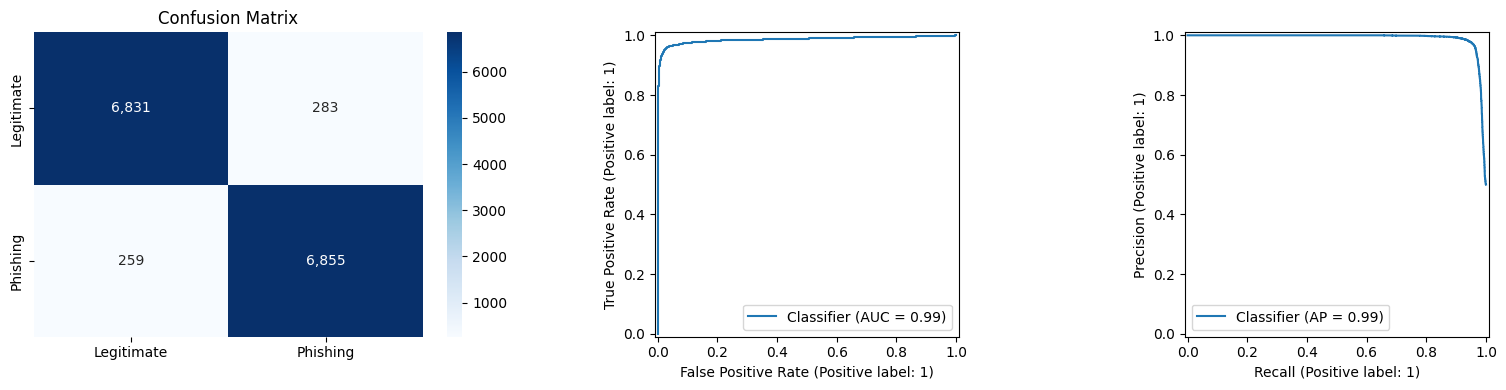

              precision    recall  f1-score   support

  legitimate       0.96      0.96      0.96      7114
    phishing       0.96      0.96      0.96      7114

    accuracy                           0.96     14228
   macro avg       0.96      0.96      0.96     14228
weighted avg       0.96      0.96      0.96     14228



In [10]:
best = models['MultinomialNB']
best_proba = best.predict_proba(X_test)[:,1]
best_pred = (best_proba >= .5).astype(int)
cm = confusion_matrix(real_test.label, best_pred)
fig, axes = plt.subplots(1,3,figsize=(16,4))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=axes[0],
            xticklabels=['Legitimate','Phishing'], yticklabels=['Legitimate','Phishing'])
axes[0].set_title('Confusion Matrix')
RocCurveDisplay.from_predictions(real_test.label,best_proba,ax=axes[1])
PrecisionRecallDisplay.from_predictions(real_test.label,best_proba,ax=axes[2])
plt.tight_layout(); plt.show()
print(classification_report(real_test.label,best_pred,
                            target_names=['legitimate','phishing']))

**Interpretasi:** model final menghasilkan TN=6,830, FP=284, FN=257, dan TP=6,857. Masih terdapat false negative; karena itu aplikasi menambahkan guard Unicode deterministik. Metrik model tidak dicampur dengan hasil guard agar pelaporan tetap jujur.

## 12. Menyimpan dan memanggil model

In [11]:
bundle = {
    'name':'MultinomialNB URL real+synthetic',
    'model':best, 'vectorizer':vectorizer, 'threshold':.5,
    'metrics':results['MultinomialNB'],
    'expects_prepared_url':True,
    'training':{'real_requested_each':50_000, 'synthetic_each':50_000,
                'split':'grouped hostname; balanced real-only test', 'seed':SEED}
}
Path('models').mkdir(exist_ok=True)
joblib.dump(bundle, 'models/final_url_model.joblib', compress=3)
loaded = joblib.load('models/final_url_model.joblib')
loaded['name'], loaded['metrics']

('MultinomialNB URL real+synthetic',
 {'accuracy': 0.9619061006466123,
  'precision': 0.9603530400672458,
  'recall': 0.9635929153781276,
  'f1': 0.9619702497895032,
  'roc_auc': 0.9859948812262548,
  'pr_auc': 0.9902269902607658})

**Interpretasi:** model dan vectorizer disimpan dalam satu bundle sehingga server localhost cukup memuatnya sekali. Training tidak dijalankan ketika pengguna membuka frontend.

## 13. Kesimpulan dan kontribusi

Penelitian sebelumnya membuktikan bahwa fitur leksikal/representasi karakter efektif untuk malicious URL, sedangkan penelitian IDN menunjukkan perlunya pemeriksaan homoglyph, skeleton, dan kebijakan skrip. Kontribusi eksperimen ini adalah menyatukan kedua arah tersebut dalam sistem ringan:

1. klasifikasi URL real + sintetis dengan Multinomial Naive Bayes;
2. data Punycode tidak diberi satu label otomatis—tersedia IDN legitimate dan homograph phishing;
3. URL diperiksa hingga hostname, path, query, IP, port, encoding, protokol, dan kata sensitif;
4. guard Unicode menangani Cyrillic, Greek, Armenian, Cherokee, fullwidth, Latin Extended, serta mixed-script;
5. test hanya menggunakan data real, seimbang, dan dipisahkan berdasarkan hostname.

Hasil final mencapai Accuracy 96,20%, Precision 96,02%, Recall 96,39%, F1 96,20%, ROC-AUC 98,62%, dan PR-AUC 99,03%. Hasil ini kuat sebagai eksperimen, tetapi bukan jaminan tidak ada phishing yang lolos. Pengembangan berikutnya perlu external/temporal test IDN nyata yang lebih besar, DNS/reputasi, umur domain, TLS, dan konten halaman.